# Rotación de empleados: ¿quién renuncia?

**Pregunta:** ¿qué grupos de empleados tienen mayor tasa de rotación?

**Datos:** IBM HR Analytics Employee Attrition (Kaggle), 1.470 empleados y 35 variables.
Para ejecutar el cuaderno, descarga el CSV de Kaggle y súbelo con el nombre Dataset1.csv.

**Herramientas:** Python, pandas y matplotlib.

## 1. Extracción y limpieza (ETL)
- Sin valores nulos ni duplicados que corregir.
- Eliminé EmployeeCount, Over18 y StandardHours: tienen un único valor y no aportan variabilidad.
- Usé EmployeeNumber como índice: identifica al empleado, pero no es una variable de análisis.
- Creé Attrition_flag (1 si renunció, 0 si no), para poder calcular tasas, y Grupo_edad.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

RUTA = "Dataset1.csv"

# ---------- EXTRACT ----------
df_raw = pd.read_csv(RUTA)
df = df_raw.copy()

# ---------- TRANSFORM ----------
df = df.drop(columns=["EmployeeCount", "Over18", "StandardHours"])
df = df.set_index("EmployeeNumber")
df["Attrition_flag"] = df["Attrition"].map({"Yes": 1, "No": 0})
df["Grupo_edad"] = pd.cut(df["Age"],
                          bins=[17, 25, 35, 45, 55, 70],
                          labels=["18-25", "26-35", "36-45", "46-55", "56+"])

# ---------- LOAD ----------
df.to_csv("hr_attrition_limpio.csv")

# ---------- Resumen por edad ----------
resumen = (df.groupby("Grupo_edad", observed=True)["Attrition_flag"]
             .agg(["count", "sum", "mean"]))
resumen.columns = ["empleados", "renuncias", "tasa"]
resumen["tasa"] = (resumen["tasa"] * 100).round(1)

# ---------- Estilo de los gráficos ----------
plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6B7B8C",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#E3E8EE",
    "axes.facecolor": "white",
    "figure.facecolor": "white",
})

print(df.shape)   # debe dar (1470, 33)

(1470, 33)


## 2. Hallazgo principal: rotación por edad
La rotación general es de 16,1 %. Al separar por edad, los menores de 26 años
destacan con 35,8 %, casi 4 veces la tasa del grupo de 36 a 45 (9,2 %).
El grupo de 56+ tiene solo 47 personas, así que su tasa es poco fiable.

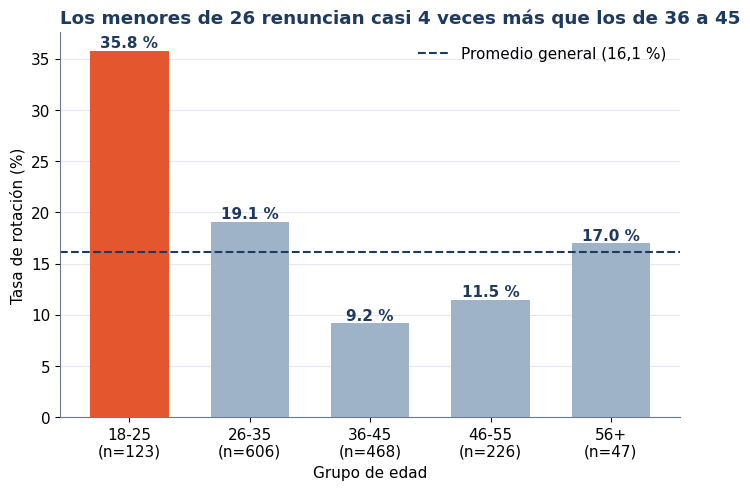

In [2]:
tasa = resumen["tasa"]
colores = ["#E4572E"] + ["#9FB3C8"] * 4   # acento solo en 18-25

ax = tasa.plot(kind="bar", figsize=(8, 5), color=colores, width=0.65)
ax.xaxis.grid(False)

linea = ax.axhline(16.1, color="#1F3A5F", linestyle="--", linewidth=1.5,
                   label="Promedio general (16,1 %)")
ax.legend(handles=[linea], frameon=False)
ax.bar_label(ax.containers[0], fmt="%.1f %%", color="#1F3A5F", fontweight="bold")

etiquetas = [f"{g}\n(n={n})" for g, n in zip(resumen.index, resumen["empleados"])]
ax.set_xticklabels(etiquetas, rotation=0)

ax.set_title("Los menores de 26 renuncian casi 4 veces más que los de 36 a 45",
             color="#1F3A5F", fontweight="bold", loc="left")
ax.set_xlabel("Grupo de edad")
ax.set_ylabel("Tasa de rotación (%)")

plt.savefig("rotacion_por_edad.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Distribución de ingresos
El promedio (6.503) es mayor que la mediana (4.919): unos pocos sueldos altos
jalan el promedio hacia arriba. Para describir al empleado típico, la mediana
es más representativa.

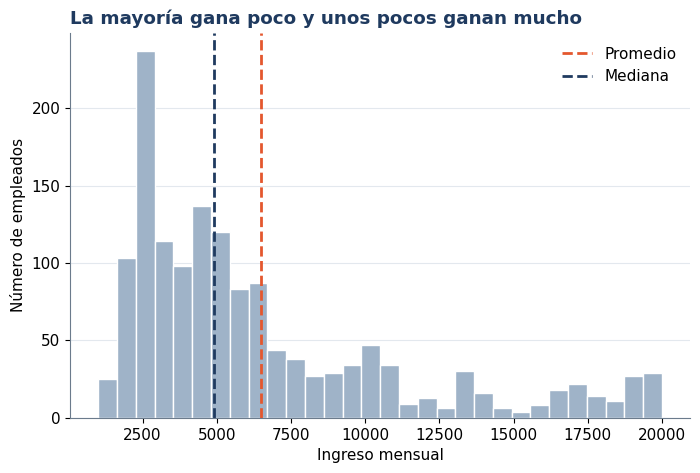

In [3]:
ax = df["MonthlyIncome"].plot(kind="hist", bins=30, color="#9FB3C8",
                              edgecolor="white", figsize=(8, 5))
ax.xaxis.grid(False)

l1 = ax.axvline(df["MonthlyIncome"].mean(), color="#E4572E", linestyle="--",
                linewidth=2, label="Promedio")
l2 = ax.axvline(df["MonthlyIncome"].median(), color="#1F3A5F", linestyle="--",
                linewidth=2, label="Mediana")
ax.legend(handles=[l1, l2], frameon=False)

ax.set_title("La mayoría gana poco y unos pocos ganan mucho",
             color="#1F3A5F", fontweight="bold", loc="left")
ax.set_xlabel("Ingreso mensual")
ax.set_ylabel("Número de empleados")

plt.savefig("distribucion_ingresos.png", dpi=200, bbox_inches="tight")
plt.show()

## Conclusiones
1. Cerca de 1 de cada 6 empleados renunció (16,1 %).
2. Los menores de 26 años tienen la tasa más alta (35,8 %).
3. Los sueldos están sesgados: la mediana representa mejor al empleado típico.

## Límites
- Los datos muestran asociaciones, no causas.
- El grupo de 56+ es pequeño (47 personas).
- Es un dataset de práctica, no datos reales de una empresa.